# Proyecto intermedio

## Parte 1. Implementacion funcion simular

### Simulación de fragmentación y coalescencia

Primer acercamiento a la solucion de los problemas de escoger grupos y realizar la separacion o unificacion.


In [10]:
import secrets
import time
from numbers import Integral, Real

import numpy as np


def simular1(N, nu, pasos, semilla=None):

    for nombre, valor, minimo in (("N", N, 1), ("pasos", pasos, 0)):
        if isinstance(valor, (bool, np.bool_)) or not isinstance(valor, Integral):
            raise TypeError(f"{nombre} debe ser un entero.")
        if valor < minimo:
            raise ValueError(f"{nombre} debe ser mayor o igual que {minimo}.")
    if isinstance(nu, (bool, np.bool_)) or not isinstance(nu, Real):
        raise TypeError("nu debe ser un número real.")
    if not np.isfinite(nu) or not 0 <= nu <= 1:
        raise ValueError("nu debe estar entre 0 y 1 y ser finito.")
    if semilla is not None:
        if isinstance(semilla, (bool, np.bool_)) or not isinstance(semilla, Integral):
            raise TypeError("semilla debe ser un entero o None.")
        if semilla < 0:
            raise ValueError("semilla debe ser no negativa.")

    N, nu, pasos = int(N), float(nu), int(pasos)
    semilla = secrets.randbits(128) if semilla is None else int(semilla)
    inicio = time.perf_counter()
    rng = np.random.default_rng(semilla)
    dueno = np.arange(N, dtype=np.int64)
    siguiente_id_libre = N

    for _ in range(pasos):
        p = rng.integers(0, N)
        g_i = dueno[p]
        if rng.random() < nu:
            miembros = np.where(dueno == g_i)[0]
            num_miembros = len(miembros)
            if num_miembros > 1:
                dueno[miembros] = np.arange(
                    siguiente_id_libre, siguiente_id_libre + num_miembros
                )
                siguiente_id_libre += num_miembros
        else:
            q = rng.integers(0, N)
            g_k = dueno[q]
            if g_i != g_k:
                dueno[dueno == g_k] = g_i

    _, tamanos = np.unique(dueno, return_counts=True)
    valores, conteos = np.unique(tamanos, return_counts=True)
    cantidad_grupos = len(tamanos)
    tamanos_grupos = tamanos.tolist()
    distribucion = {
        int(tamano): {
            "cantidad": int(conteo),
            "frecuencia_relativa": float(conteo / cantidad_grupos),
        }
        for tamano, conteo in zip(valores, conteos)
    }
    tiempo = time.perf_counter() - inicio
    return {
        "parametros": {"N": N, "nu": nu, "pasos": pasos},
        "semilla": semilla,
        "tiempo_ejecucion_segundos": tiempo,
        "tamanos_grupos": tamanos_grupos,
        "cantidad_grupos": cantidad_grupos,
        "distribucion_tamanos": distribucion,
    }


### Experimento reproducible

El ejemplo usa valores pequeños para ejecutarse rápidamente. Para los parámetros originales: `simular(N=10000, nu=0.01, pasos=1000000)`. Esta ejecución puede tardar considerablemente más.


In [11]:
resultado1 = simular1(N=100, nu=0.01, pasos=1000, semilla=42)
resultado1


{'parametros': {'N': 100, 'nu': 0.01, 'pasos': 1000},
 'semilla': 42,
 'tiempo_ejecucion_segundos': 0.011030666999886307,
 'tamanos_grupos': [100],
 'cantidad_grupos': 1,
 'distribucion_tamanos': {100: {'cantidad': 1, 'frecuencia_relativa': 1.0}}}

### Semilla automática y repetición

Guarda la semilla devuelta junto con los parámetros y la versión de NumPy. La distribución cuenta grupos, no individuos; sus frecuencias relativas suman 1. La suma de todos los tamaños siempre es N. Los identificadores internos no se exponen como posiciones persistentes entre experimentos.


In [12]:
aleatorio = simular1(N=100, nu=0.1, pasos=1000)
repetido = simular1(**aleatorio['parametros'], semilla=aleatorio['semilla'])
assert aleatorio['tamanos_grupos'] == repetido['tamanos_grupos']
assert sum(aleatorio['tamanos_grupos']) == aleatorio['parametros']['N']
aleatorio['semilla'], aleatorio['distribucion_tamanos']


(65604771413646854515372251044067232749,
 {1: {'cantidad': 29, 'frecuencia_relativa': 0.9354838709677419},
  2: {'cantidad': 1, 'frecuencia_relativa': 0.03225806451612903},
  69: {'cantidad': 1, 'frecuencia_relativa': 0.03225806451612903}})

## Parte 2. Numero de pasos eficaces

## optimizacion codigo
Se implementó una versión optimizada del algoritmo de coalescencia y fragmentación, que presentó una mejora de rendimiento respecto a la implementación original en las pruebas realizadas. Posteriormente, se estudió la evolución temporal del número de grupos para identificar un posible régimen estacionario.


In [13]:

import numpy as np
import time
import secrets

def simular2(N, nu, pasos, semilla=None):
    if N < 1 or pasos < 0 or not 0 <= nu <= 1:
        raise ValueError("N debe ser positivo, pasos no negativo y nu entre 0 y 1.")

    if semilla is None:
        semilla = secrets.randbits(128)

    rng = np.random.default_rng(semilla)
    inicio = time.perf_counter()

    # Inicialmente hay N grupos de una unidad cada uno.
    grupos = {i: [i] for i in range(N)}
    owner = np.arange(N, dtype=np.int64)
    siguiente_id = N

    for _ in range(pasos):
        p = int(rng.integers(N))
        gid = int(owner[p])

        if rng.random() < nu:  # Fragmentación
            miembros = grupos.pop(gid)

            if len(miembros) > 1:
                for unidad in miembros:
                    grupos[siguiente_id] = [unidad]
                    owner[unidad] = siguiente_id
                    siguiente_id += 1
            else:
                grupos[gid] = miembros

        else:  # Coalescencia
            q = int(rng.integers(N))
            otro_gid = int(owner[q])

            if gid != otro_gid:
                # Fusionar el grupo pequeño con el grande.
                if len(grupos[gid]) < len(grupos[otro_gid]):
                    gid, otro_gid = otro_gid, gid

                movidos = grupos.pop(otro_gid)
                grupos[gid].extend(movidos)
                owner[movidos] = gid

    # Resultados
    tamanos = np.fromiter(
        (len(miembros) for miembros in grupos.values()),
        dtype=np.int64
    )

    valores, cantidades = np.unique(tamanos, return_counts=True)
    numero_grupos = len(grupos)

    distribucion = {
        int(s): {
            "count": int(c),
            "relative_frequency": float(c / numero_grupos)
        }
        for s, c in zip(valores, cantidades)
    }

    return {
        "parametros": {"N": N, "nu": nu, "pasos": pasos},
        "semilla": semilla,
        "tiempo_ejecucion_segundos": time.perf_counter() - inicio,
        "tamanos_grupos": tamanos,
        "cantidad_grupos": numero_grupos,
        "distribucion_tamanos": distribucion
    }


### Comparacion

Se comparan los tiempos de los dos algoritmos para comprobar cual es mas eficiente y que sigan cumpliendo las condiciones del problema

In [20]:

N = 10000
nu = 0.01
pasos = 2000000
semilla = 42

def probar(nombre, funcion):
    inicio = time.perf_counter()
    resultado = funcion(N, nu, pasos, semilla)
    tiempo = time.perf_counter() - inicio

    tamanos = resultado["tamanos_grupos"]

    # Comprobar que todas las unidades siguen presentes
    assert sum(tamanos) == N, "Error: no se conserva el total de unidades."

    # Comprobar que el número de grupos coincide
    assert len(tamanos) == resultado["cantidad_grupos"], (
        "Error: el número de grupos no coincide."
    )

    assert sum(tamanos) == N

    print(f"\n{nombre}")
    print(f"Tiempo medido: {tiempo:.3f} segundos")
    print(
        f"Tiempo informado: "
        f"{resultado['tiempo_ejecucion_segundos']:.3f} segundos"
    )
    print(f"Grupos finales: {resultado['cantidad_grupos']}")
    print("Comprobaciones: correctas")

    return resultado, tiempo


r1, t1 = probar("simular1 (original)", simular1)
r2, t2 = probar("simular2 (optimizada)", simular2)

print(f"Tiempo original:   {t1:.3f} s")
print(f"Tiempo optimizado: {t2:.3f} s")




simular1 (original)
Tiempo medido: 12.519 segundos
Tiempo informado: 12.519 segundos
Grupos finales: 6764
Comprobaciones: correctas

simular2 (optimizada)
Tiempo medido: 6.278 segundos
Tiempo informado: 6.278 segundos
Grupos finales: 6764
Comprobaciones: correctas
Tiempo original:   12.519 s
Tiempo optimizado: 6.278 s


### Intento de estimacion, pasos optimos

Se intento crear una funcion que recibiera $\nu$ y N y devolviera el paso optimo donde se estabilice la simulacion, pero tuvo complicaciones a la hora de desarrollarla, pues se trato de mostrar primero con promedio de cambio de cantidades de grupos en intervalos de tiempos, luego con desviacion estandar tambien se trato, pero en general se ve un comportamiento dificil de estimar un punto de estabilidad. El criterio automático de estabilización implementado inicialmente resultó insuficiente, pues podía detectar estabilidad aparente mientras persistían variaciones importantes en el sistema.

Por consiguiente, el número óptimo de pasos no se presenta como una cantidad determinada. Su estimación requiere un análisis adicional que considere la distribución de tamaños de los grupos, la variabilidad entre simulaciones independientes y la sensibilidad de los resultados al numero de pasos elegidos.

Para las pruebas computacionales se utilizará un número de pasos definido experimentalmente, de acuerdo con los requisitos del proyecto y con la viabilidad computacional. Este valor se entenderá como el limite de simulacion seleccionado, y no como una demostración de que el sistema haya alcanzado el equilibrio.

In [21]:

import numpy as np
import matplotlib.pyplot as plt
import secrets
import time


def estimar_pasos_optimos(
    N,
    nu,
    pasos_max=500_000,
    semilla=None,
    registro_cada=None,
    ventana=20,
    tolerancia=0.01,
    paciencia=3,
    graficar=True
):

    if N < 1 or pasos_max < 0:
        raise ValueError("N debe ser positivo y pasos_max no negativo.")
    if not 0 <= nu <= 1:
        raise ValueError("nu debe estar entre 0 y 1.")
    if ventana < 2 or paciencia < 1:
        raise ValueError("ventana debe ser >= 2 y paciencia >= 1.")
    if tolerancia < 0:
        raise ValueError("La tolerancia no puede ser negativa.")

    if semilla is None:
        semilla = secrets.randbits(128)

    if registro_cada is None:
        registro_cada = max(1, N // 10)

    if registro_cada < 1:
        raise ValueError("registro_cada debe ser positivo.")

    rng = np.random.default_rng(semilla)
    inicio = time.perf_counter()

    # Estado inicial
    grupos = {i: [i] for i in range(N)}
    owner = np.arange(N, dtype=np.int64)
    siguiente_id = N

    tiempos = [0]
    cantidad_grupos = [N]

    # Casos donde ya se conoce el comportamiento
    if nu == 1 or N == 1 or pasos_max == 0:
        pasos = 0
        estabilizado = True
    else:
        pasos = 0
        comparaciones_estables = 0
        estabilizado = False

        muestras_necesarias = 2 * ventana

        for paso in range(1, pasos_max + 1):
            p = int(rng.integers(N))
            gid = int(owner[p])

            if rng.random() < nu:
                # Fragmentación
                miembros = grupos.pop(gid)

                if len(miembros) > 1:
                    for unidad in miembros:
                        grupos[siguiente_id] = [unidad]
                        owner[unidad] = siguiente_id
                        siguiente_id += 1
                else:
                    grupos[gid] = miembros

            else:
                # Coalescencia: se elige otra unidad al azar
                q = int(rng.integers(N))
                otro_gid = int(owner[q])

                if gid != otro_gid:
                    # Fusionar el grupo menor dentro del mayor
                    if len(grupos[gid]) < len(grupos[otro_gid]):
                        gid, otro_gid = otro_gid, gid

                    movidos = grupos.pop(otro_gid)
                    grupos[gid].extend(movidos)
                    owner[movidos] = gid

            # Registrar la evolución cada cierto número de pasos
            if paso % registro_cada == 0 or paso == pasos_max:
                tiempos.append(paso)
                cantidad_grupos.append(len(grupos))

            # Detectar estabilización mediante promedios consecutivos
            if len(cantidad_grupos) >= muestras_necesarias:
                datos = np.asarray(cantidad_grupos[-muestras_necesarias:])

                media_anterior = np.mean(datos[:ventana])
                media_reciente = np.mean(datos[ventana:])

                cambio_relativo = (
                    abs(media_reciente - media_anterior)
                    / max(abs(media_anterior), 1e-12)
                )

                if cambio_relativo <= tolerancia:
                    comparaciones_estables += 1
                else:
                    comparaciones_estables = 0

                if comparaciones_estables >= paciencia:
                    pasos = paso
                    estabilizado = True
                    break

        if pasos == 0:
            pasos = min(paso, pasos_max)

    tiempo_ejecucion = time.perf_counter() - inicio

    if tiempos[-1] != pasos:
        tiempos.append(pasos)
        cantidad_grupos.append(len(grupos))

    if graficar:
        plt.figure(figsize=(11, 5))
        plt.plot(tiempos, cantidad_grupos, linewidth=1.5)
        plt.axvline(
            pasos,
            linestyle="--",
            label=f"Detección: {pasos:,} pasos"
        )
        plt.xlabel("Número de pasos")
        plt.ylabel("Cantidad de grupos")
        plt.title(f"Evolución de los grupos (N={N}, nu={nu})")
        plt.grid(True, alpha=0.3)
        plt.legend()
        plt.tight_layout()
        plt.show()

    resultado = {
        "N": N,
        "nu": nu,
        "pasos_estimados": pasos,
        "estabilizado": estabilizado,
        "pasos_max": pasos_max,
        "semilla": semilla,
        "tiempos": np.asarray(tiempos),
        "cantidad_grupos": np.asarray(cantidad_grupos),
        "grupos_finales": len(grupos),
        "tiempo_ejecucion_segundos": tiempo_ejecucion
    }

    if estabilizado:
        print(f"Estabilización detectada en el paso {pasos:,}.")
    else:
        print(
            f"No se detectó estabilización antes del límite "
            f"de {pasos:,} pasos."
        )

    print(f"Grupos al finalizar: {len(grupos)}")
    print(f"Tiempo de ejecución: {tiempo_ejecucion:.3f} segundos")

    return resultado


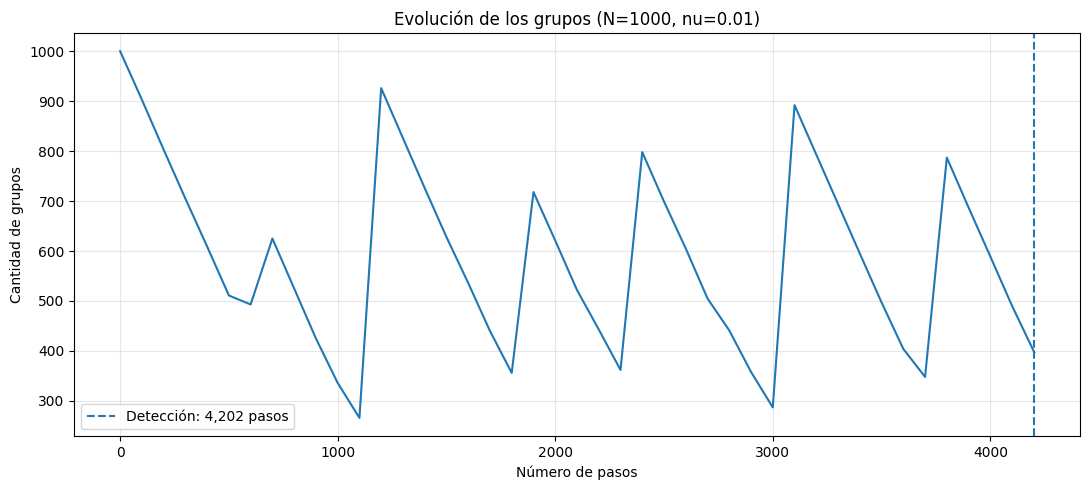

Estabilización detectada en el paso 4,202.
Grupos al finalizar: 397
Tiempo de ejecución: 0.042 segundos


In [26]:
resultado = estimar_pasos_optimos(
    N=1000,
    nu=0.01,
    pasos_max=200_000,
    semilla=42
)

Promedio de grupos por segmento:

Segmento 1: pasos 0–1200, promedio=625.15, mínimo=266, máximo=1000
Segmento 2: pasos 1300–2500, promedio=590.38, mínimo=356, máximo=826
Segmento 3: pasos 2600–3800, promedio=554.31, mínimo=287, máximo=892
Segmento 4: pasos 3900–5100, promedio=580.77, mínimo=321, máximo=816
Segmento 5: pasos 5200–6204, promedio=553.42, mínimo=297, máximo=857


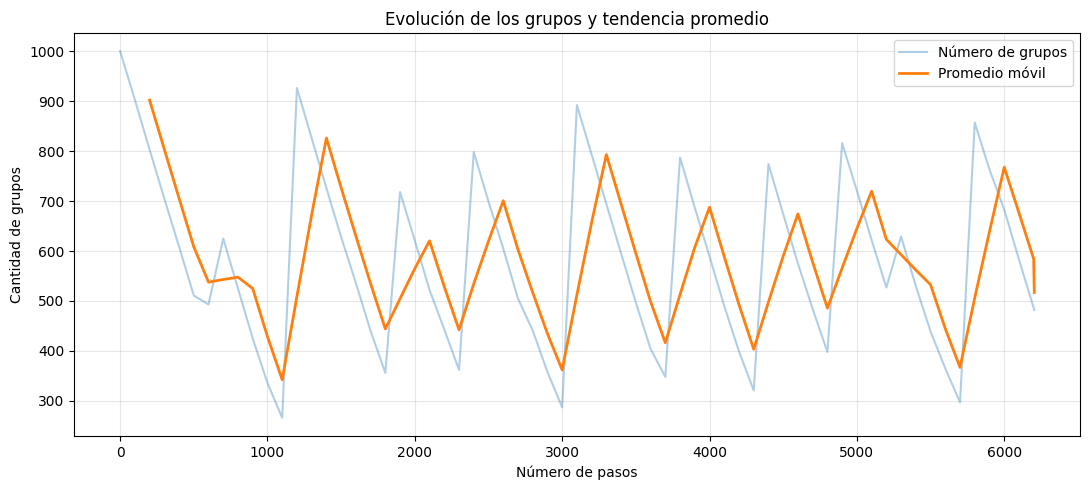

In [31]:
tiempos = resultado_largo["tiempos"]
grupos = resultado_largo["cantidad_grupos"]

segmentos = np.array_split(np.arange(len(tiempos)), 5)

print("Promedio de grupos por segmento:\n")

for i, indices in enumerate(segmentos, start=1):
    if len(indices) == 0:
        continue

    media = np.mean(grupos[indices])
    minimo = np.min(grupos[indices])
    maximo = np.max(grupos[indices])

    print(
        f"Segmento {i}: "
        f"pasos {tiempos[indices[0]]}–{tiempos[indices[-1]]}, "
        f"promedio={media:.2f}, "
        f"mínimo={minimo}, máximo={maximo}"
    )

plt.figure(figsize=(11, 5))
plt.plot(tiempos, grupos, alpha=0.35, label="Número de grupos")

# Promedio móvil para observar la tendencia
if len(grupos) >= 10:
    ancho = max(3, len(grupos) // 20)
    promedio_movil = np.convolve(
        grupos, np.ones(ancho) / ancho, mode="valid"
    )
    plt.plot(
        tiempos[ancho - 1:],
        promedio_movil,
        linewidth=2,
        label="Promedio móvil"
    )

plt.xlabel("Número de pasos")
plt.ylabel("Cantidad de grupos")
plt.title("Evolución de los grupos y tendencia promedio")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


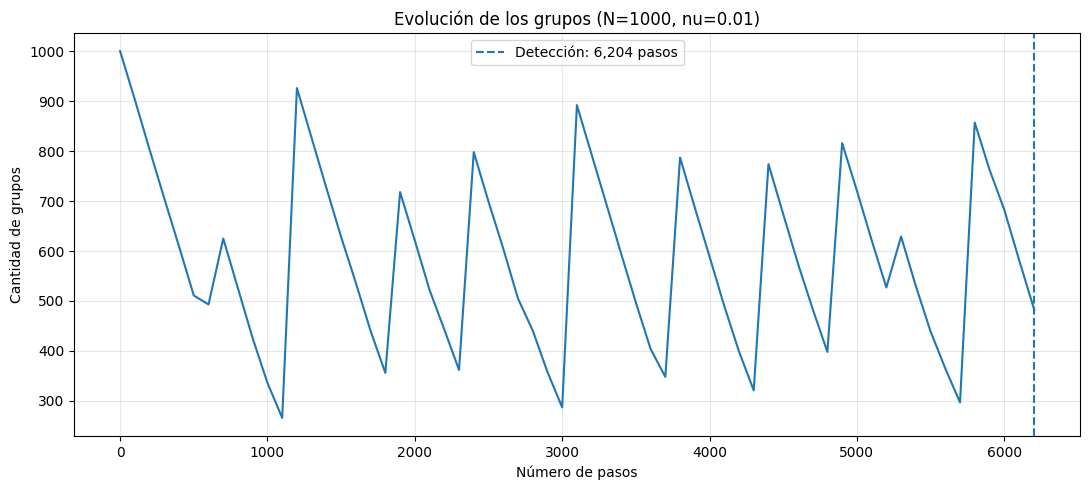

Estabilización detectada en el paso 6,204.
Grupos al finalizar: 482
Tiempo de ejecución: 0.050 segundos


In [30]:

resultado_largo = estimar_pasos_optimos(
    N=1000,
    nu=0.01,
    pasos_max=50_000,
    semilla=42,
    registro_cada=100,
    ventana=30,
    tolerancia=0.01,
    paciencia=5,
    graficar=True
)


In [32]:

print("Pasos estimados:", resultado_largo["pasos_estimados"])
print("Límite solicitado:", resultado_largo["pasos_max"])
print("¿Detectó estabilización?:", resultado_largo["estabilizado"])
print("Último paso registrado:", resultado_largo["tiempos"][-1])
print("Número de registros:", len(resultado_largo["tiempos"]))


Pasos estimados: 6204
Límite solicitado: 50000
¿Detectó estabilización?: True
Último paso registrado: 6204
Número de registros: 64


Pasos ejecutados: 50,000
Grupos finales: 501
Tiempo de ejecución: 0.20 segundos


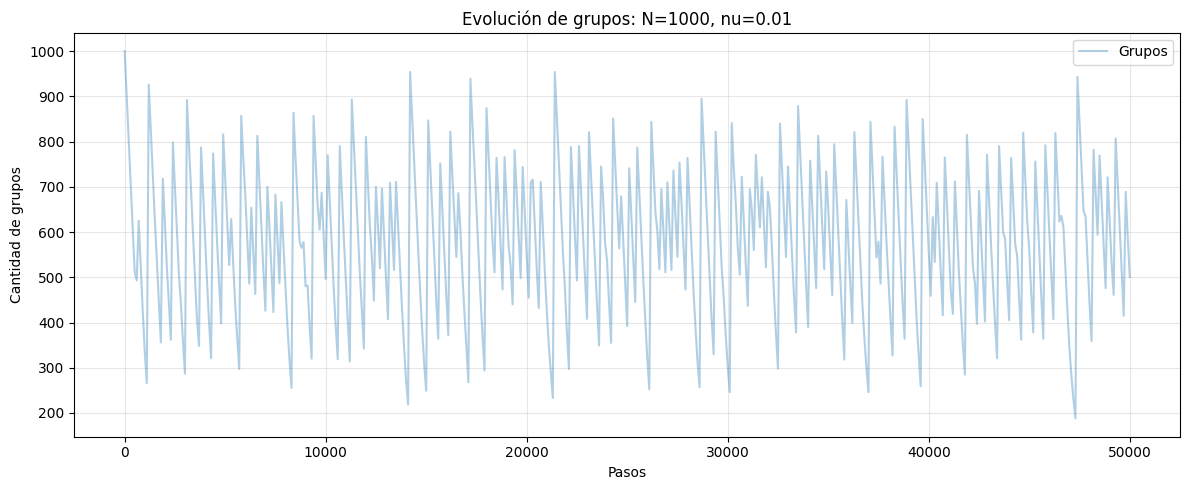

In [33]:
N = 1000
nu = 0.01
pasos = 50_000
semilla = 42

rng = np.random.default_rng(semilla)

grupos = {i: [i] for i in range(N)}
owner = np.arange(N, dtype=np.int64)
siguiente_id = N

registro_cada = 100
tiempos = [0]
cantidad_grupos = [N]

inicio = time.perf_counter()

for paso in range(1, pasos + 1):
    p = int(rng.integers(N))
    gid = int(owner[p])

    if rng.random() < nu:
        miembros = grupos.pop(gid)

        if len(miembros) > 1:
            for unidad in miembros:
                grupos[siguiente_id] = [unidad]
                owner[unidad] = siguiente_id
                siguiente_id += 1
        else:
            grupos[gid] = miembros

    else:
        q = int(rng.integers(N))
        otro_gid = int(owner[q])

        if gid != otro_gid:
            if len(grupos[gid]) < len(grupos[otro_gid]):
                gid, otro_gid = otro_gid, gid

            movidos = grupos.pop(otro_gid)
            grupos[gid].extend(movidos)
            owner[movidos] = gid

    if paso % registro_cada == 0:
        tiempos.append(paso)
        cantidad_grupos.append(len(grupos))

if tiempos[-1] != pasos:
    tiempos.append(pasos)
    cantidad_grupos.append(len(grupos))

tiempo_total = time.perf_counter() - inicio

print(f"Pasos ejecutados: {pasos:,}")
print(f"Grupos finales: {len(grupos)}")
print(f"Tiempo de ejecución: {tiempo_total:.2f} segundos")

plt.figure(figsize=(12, 5))
plt.plot(tiempos, cantidad_grupos, alpha=0.35, label="Grupos")
plt.xlabel("Pasos")
plt.ylabel("Cantidad de grupos")
plt.title(f"Evolución de grupos: N={N}, nu={nu}")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


Promedios por bloques:
Alrededor del paso 2,450: media=584.30, desviación=183.76
Alrededor del paso 7,450: media=575.96, desviación=147.57
Alrededor del paso 12,450: media=566.22, desviación=170.32
Alrededor del paso 17,450: media=597.54, desviación=164.34
Alrededor del paso 22,450: media=580.00, desviación=162.19
Alrededor del paso 27,450: media=577.12, desviación=157.77
Alrededor del paso 32,450: media=605.20, desviación=146.69
Alrededor del paso 37,450: media=570.56, desviación=170.51
Alrededor del paso 42,450: media=565.14, desviación=136.67
Alrededor del paso 47,450: media=579.06, desviación=164.08


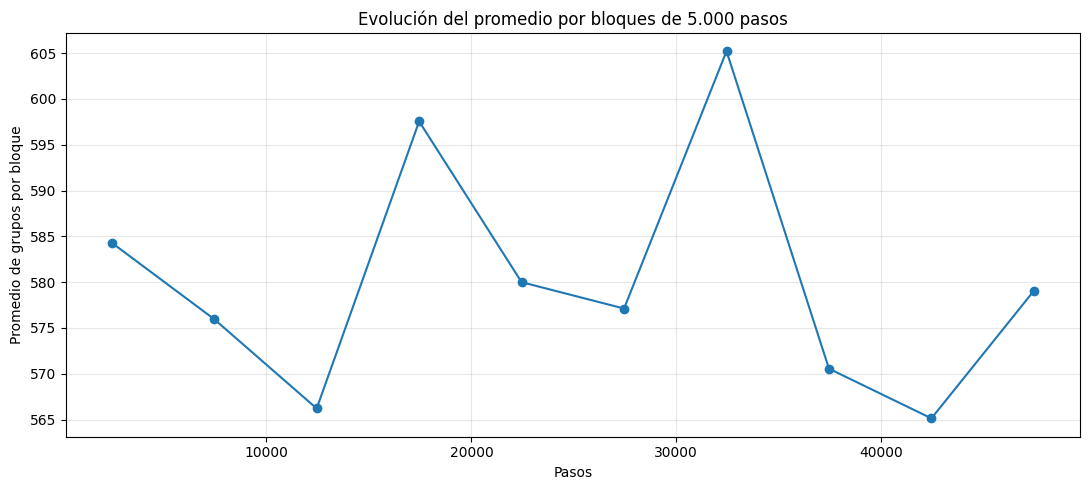

In [34]:
tiempos = np.asarray(tiempos)
grupos = np.asarray(cantidad_grupos)

# Promedios en bloques de 5.000 pasos
ancho_bloque = 5_000
limite = tiempos[-1]

inicios = np.arange(0, limite, ancho_bloque)
medias = []
desviaciones = []
centros = []

for inicio in inicios:
    fin = min(inicio + ancho_bloque, limite)

    mascara = (tiempos >= inicio) & (tiempos < fin)

    if np.any(mascara):
        datos = grupos[mascara]
        medias.append(np.mean(datos))
        desviaciones.append(np.std(datos))
        centros.append(np.mean(tiempos[mascara]))

print("Promedios por bloques:")
for centro, media, desv in zip(centros, medias, desviaciones):
    print(
        f"Alrededor del paso {centro:,.0f}: "
        f"media={media:.2f}, desviación={desv:.2f}"
    )

plt.figure(figsize=(11, 5))
plt.plot(centros, medias, marker="o")
plt.xlabel("Pasos")
plt.ylabel("Promedio de grupos por bloque")
plt.title("Evolución del promedio por bloques de 5.000 pasos")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


## Parte3. Analisis resultados